# Tema 2 - Laborator 3: Probabilități Condiționate. Formula lui Bayes
În această temă vom calcula probabilități condiționate, vom aplica formula lui Bayes și vom vedea cum agregarea datelor poate duce la concluzii înșelătoare (paradoxul lui Simpson). Pentru fiecare exercițiu facem întâi calculul teoretic, apoi îl verificăm în Python.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Seed pentru reproducibilitate
np.random.seed(12)

# Exercițiul 1: Aruncarea a Două Zaruri

## Calculele teoretice (foaia de lucru)
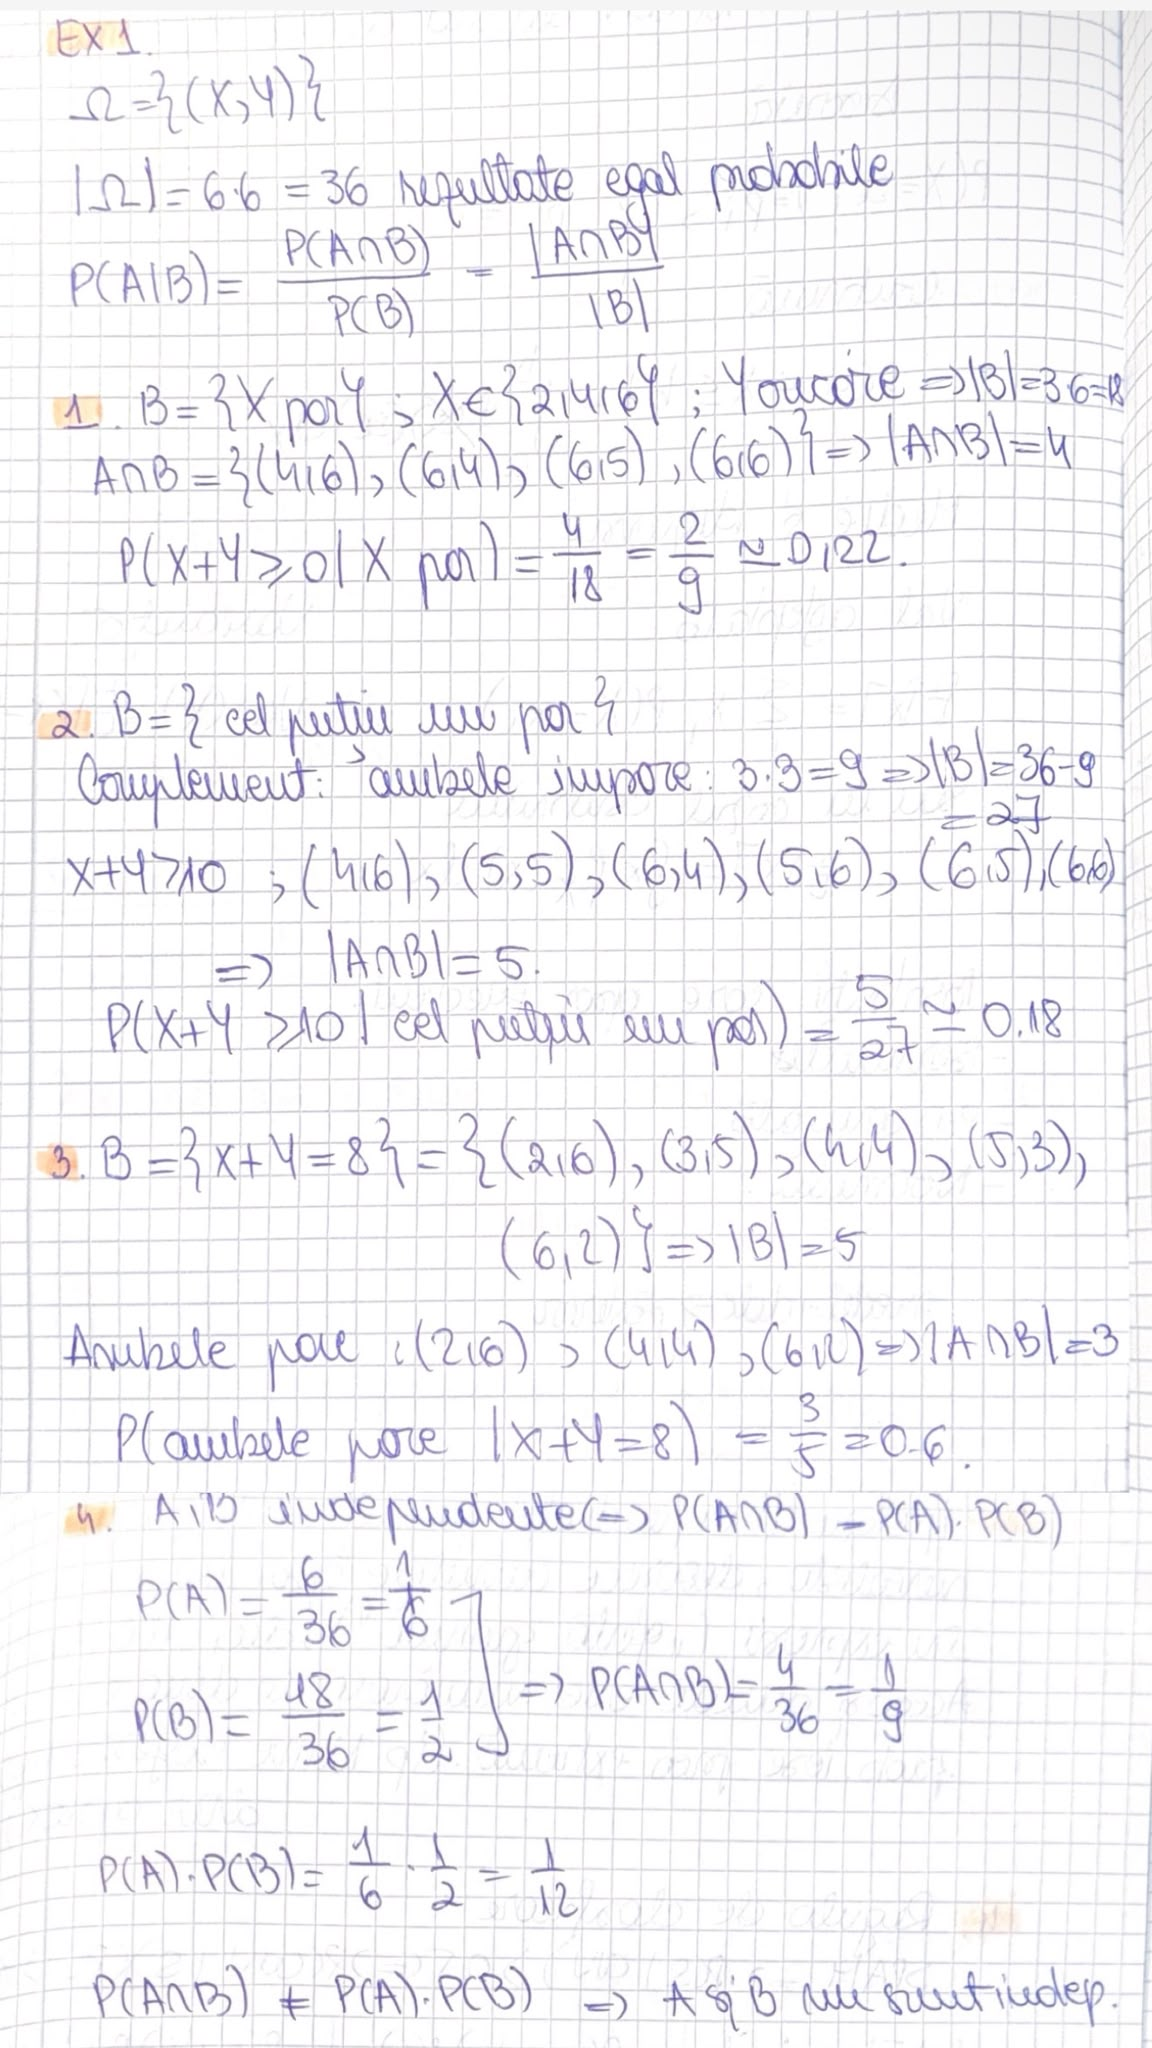

Să presupunem că aruncăm două zaruri corecte și notăm rezultatele cu $X$ (primul zar) și $Y$ (al doilea zar). Fiecare dintre cele $6 \cdot 6 = 36$ perechi $(X, Y)$ are aceeași probabilitate, $1/36$.

Când aflăm o informație suplimentară (de exemplu, că primul zar este par), spațiul de rezultate se restrânge doar la cazurile compatibile cu acea informație. De aceea, pentru evenimente din acest spațiu folosim:

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)} = \frac{|A \cap B|}{|B|}$$

Obiectivul nostru: Să calculăm probabilitățile condiționate cerute, să verificăm dacă două evenimente sunt independente și să comparăm rezultatele cu o simulare de 100.000 de aruncări.

## 1.1. Suma este cel puțin 10, știind că primul zar este par
Restrângem spațiul la cazurile în care $X$ este par:
- $B = \{X \text{ par}\}$: $X \in \{2, 4, 6\}$, iar $Y$ poate fi oricare, deci $|B| = 3 \cdot 6 = 18$.
- Dintre acestea, suma este cel puțin 10 pentru: $(4,6), (6,4), (6,5), (6,6)$, deci $|A \cap B| = 4$.

$$P(X+Y \geq 10 \mid X \text{ par}) = \frac{4}{18} = \frac{2}{9} \approx 0.2222$$

## 1.2. Suma este cel puțin 10, știind că cel puțin un zar este par
- Calculăm prin complement: „niciun zar par” înseamnă ambele impare, adică $3 \cdot 3 = 9$ cazuri. Deci $|B| = 36 - 9 = 27$.
- Sumele cel puțin 10 sunt: $(4,6), (5,5), (6,4), (5,6), (6,5), (6,6)$. Toate au cel puțin un zar par, cu excepția lui $(5,5)$, deci $|A \cap B| = 5$.

$$P(X+Y \geq 10 \mid \text{cel puțin un par}) = \frac{5}{27} \approx 0.1852$$

## 1.3. Ambele zaruri sunt pare, știind că suma este 8
- $B = \{X + Y = 8\}$: $(2,6), (3,5), (4,4), (5,3), (6,2)$, deci $|B| = 5$.
- Ambele pare: $(2,6), (4,4), (6,2)$, deci $|A \cap B| = 3$.

$$P(\text{ambele pare} \mid X+Y = 8) = \frac{3}{5} = 0.6$$

## 1.4. Sunt independente $A = \{X + Y \geq 10\}$ și $B = \{X \text{ par}\}$?
Două evenimente sunt independente dacă $P(A \cap B) = P(A) \cdot P(B)$, adică dacă informația despre unul nu schimbă probabilitatea celuilalt.

- $P(A) = \dfrac{6}{36} = \dfrac{1}{6}$, $\quad P(B) = \dfrac{18}{36} = \dfrac{1}{2}$, $\quad P(A \cap B) = \dfrac{4}{36} = \dfrac{1}{9}$
- $P(A) \cdot P(B) = \dfrac{1}{6} \cdot \dfrac{1}{2} = \dfrac{1}{12} \neq \dfrac{1}{9}$

**Evenimentele NU sunt independente.** Echivalent: $P(A \mid B) = \dfrac{2}{9} \neq P(A) = \dfrac{1}{6}$. Faptul că primul zar este par crește șansa ca suma să fie cel puțin 10.

## 1.5. Extensie Python: Simularea a 100.000 de Aruncări
Pentru a verifica rezultatele teoretice, simulăm 100.000 de aruncări ale celor două zaruri și estimăm probabilitățile condiționate prin numărare.

In [2]:
N = 100_000

#aruncăm cele două zaruri de N ori
X = np.random.randint(1, 7, size=N)
Y = np.random.randint(1, 7, size=N)

#evenimentele (vectori de True / False)
suma_10 = (X + Y) >= 10
X_par = (X % 2 == 0)
Y_par = (Y % 2 == 0)
cel_putin_un_par = X_par | Y_par
ambele_pare = X_par & Y_par
suma_8 = (X + Y) == 8

#P(A | B) = (de câte ori apar A și B) / (de câte ori apare B)
p1 = np.sum(suma_10 & X_par) / np.sum(X_par)
p2 = np.sum(suma_10 & cel_putin_un_par) / np.sum(cel_putin_un_par)
p3 = np.sum(ambele_pare & suma_8) / np.sum(suma_8)

#1.4: independența
P_A = np.mean(suma_10)
P_B = np.mean(X_par)
P_AB = np.mean(suma_10 & X_par)

print("Estimăm probabilitățile prin simulare...")
print(f"1.1. P(X+Y >= 10 | X par)             = {p1:.4f}")
print(f"1.2. P(X+Y >= 10 | cel puțin un par)  = {p2:.4f}")
print(f"1.3. P(ambele pare | X+Y = 8)         = {p3:.4f}")
print(f"1.4. P(A ∩ B) = {P_AB:.4f},  P(A) * P(B) = {P_A * P_B:.4f}")

Estimăm probabilitățile prin simulare...
1.1. P(X+Y >= 10 | X par)             = 0.2235
1.2. P(X+Y >= 10 | cel puțin un par)  = 0.1861
1.3. P(ambele pare | X+Y = 8)         = 0.6010
1.4. P(A ∩ B) = 0.1121,  P(A) * P(B) = 0.0834


### Explicații:
- `np.random.randint(1, 7, size=N)`: simulează N aruncări ale unui zar (valori de la 1 la 6).
- `X % 2 == 0`: verifică dacă rezultatul este par.
- `&` înseamnă „și”, iar `|` înseamnă „sau”.
- Probabilitatea condiționată se estimează numărând: dintre aruncările în care s-a întâmplat $B$, în câte s-a întâmplat și $A$.
- `np.mean` aplicat unui vector de True/False dă proporția valorilor True, adică probabilitatea estimată.

## Vizualizarea Datelor
Înainte de a compara rezultatele, este util să vedem cum sunt distribuite sumele celor două zaruri.

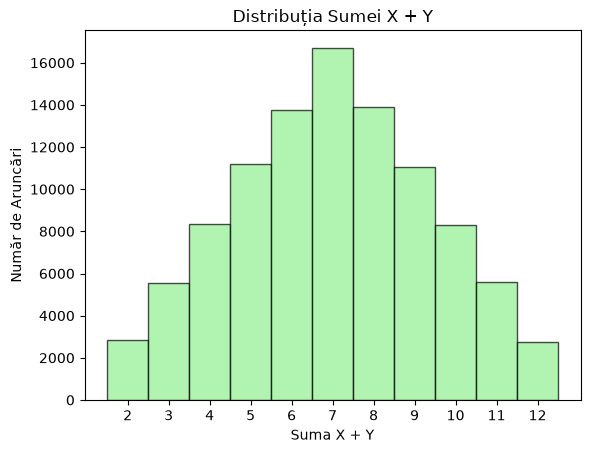

In [3]:
#afișăm histograma sumelor X + Y
plt.hist(X + Y, bins=np.arange(1.5, 13.5, 1), alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Distribuția Sumei X + Y')
plt.xlabel('Suma X + Y')
plt.ylabel('Număr de Aruncări')
plt.xticks(range(2, 13))
plt.show()

### Interpretare:
- Suma 7 este cea mai frecventă (6 combinații din 36), iar sumele 2 și 12 sunt cele mai rare (câte o singură combinație).
- Sumele cel puțin 10 (10, 11, 12) apar în $3 + 2 + 1 = 6$ cazuri din 36, adică $P(X+Y \geq 10) = 1/6$.

## Compararea Valorilor Estimate cu Cele Exacte

In [4]:
#comparăm valorile estimate cu valorile exacte
exacte = [2/9, 5/27, 3/5, 1/9]
estimate = [p1, p2, p3, P_AB]
nume = ['1.1. P(X+Y≥10 | X par)', '1.2. P(X+Y≥10 | ≥1 par)', '1.3. P(ambele pare | X+Y=8)', '1.4. P(A ∩ B)']

tabel = pd.DataFrame({'Valoare exactă': exacte, 'Valoare estimată': estimate}, index=nume)
tabel['Diferența'] = abs(tabel['Valoare exactă'] - tabel['Valoare estimată'])
print(tabel.round(4))

                             Valoare exactă  Valoare estimată  Diferența
1.1. P(X+Y≥10 | X par)               0.2222            0.2235     0.0013
1.2. P(X+Y≥10 | ≥1 par)              0.1852            0.1861     0.0010
1.3. P(ambele pare | X+Y=8)          0.6000            0.6010     0.0010
1.4. P(A ∩ B)                        0.1111            0.1121     0.0010


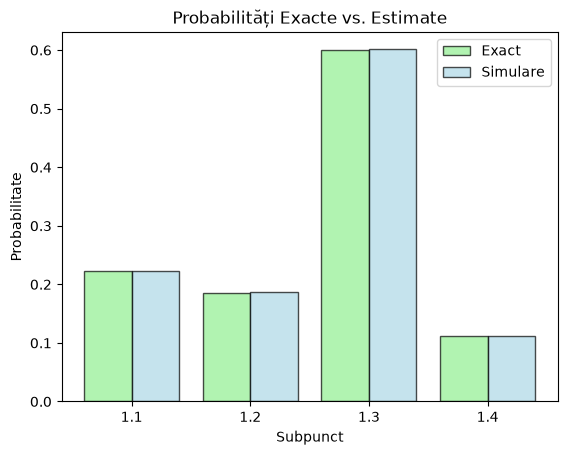

In [5]:
#afișăm comparația grafic
x = np.arange(len(nume))
plt.bar(x - 0.2, exacte, width=0.4, alpha=0.7, color='lightgreen', edgecolor='black', label='Exact')
plt.bar(x + 0.2, estimate, width=0.4, alpha=0.7, color='lightblue', edgecolor='black', label='Simulare')
plt.xticks(x, ['1.1', '1.2', '1.3', '1.4'])
plt.title('Probabilități Exacte vs. Estimate')
plt.xlabel('Subpunct')
plt.ylabel('Probabilitate')
plt.legend()
plt.show()

### Interpretare:
- Valorile estimate prin simulare sunt foarte apropiate de cele exacte (diferențe de ordinul 0.001).
- La punctul 1.4, $P(A \cap B) \approx 0.111$, iar $P(A) \cdot P(B) \approx 0.083$: simularea confirmă că evenimentele **nu** sunt independente.

## Convergența Estimării
Cum se apropie estimarea lui $P(X+Y \geq 10 \mid X \text{ par})$ de valoarea exactă pe măsură ce creștem numărul de aruncări.

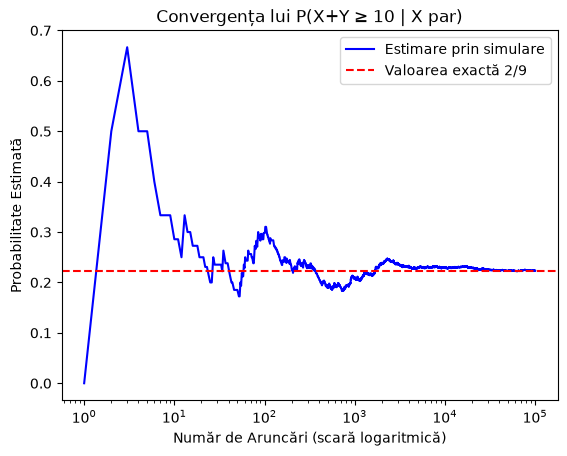

In [6]:
#estimarea după primele n aruncări, pentru fiecare n
estimare_cumulata = np.cumsum(suma_10 & X_par) / np.maximum(np.cumsum(X_par), 1)

plt.plot(range(1, N + 1), estimare_cumulata, color='blue', label='Estimare prin simulare')
plt.axhline(2/9, color='red', linestyle='--', label='Valoarea exactă 2/9')
plt.xscale('log')
plt.title('Convergența lui P(X+Y ≥ 10 | X par)')
plt.xlabel('Număr de Aruncări (scară logaritmică)')
plt.ylabel('Probabilitate Estimată')
plt.legend()
plt.show()

### Interpretare:
La început estimarea oscilează mult, dar pe măsură ce numărul de aruncări crește, se stabilizează în jurul valorii exacte $2/9 \approx 0.222$. Este legea numerelor mari: cu cât repetăm experimentul de mai multe ori, cu atât frecvența relativă se apropie de probabilitatea reală.

# Exercițiul 2: Filtrarea Mesajelor Spam

## Calculele teoretice (foaia de lucru)
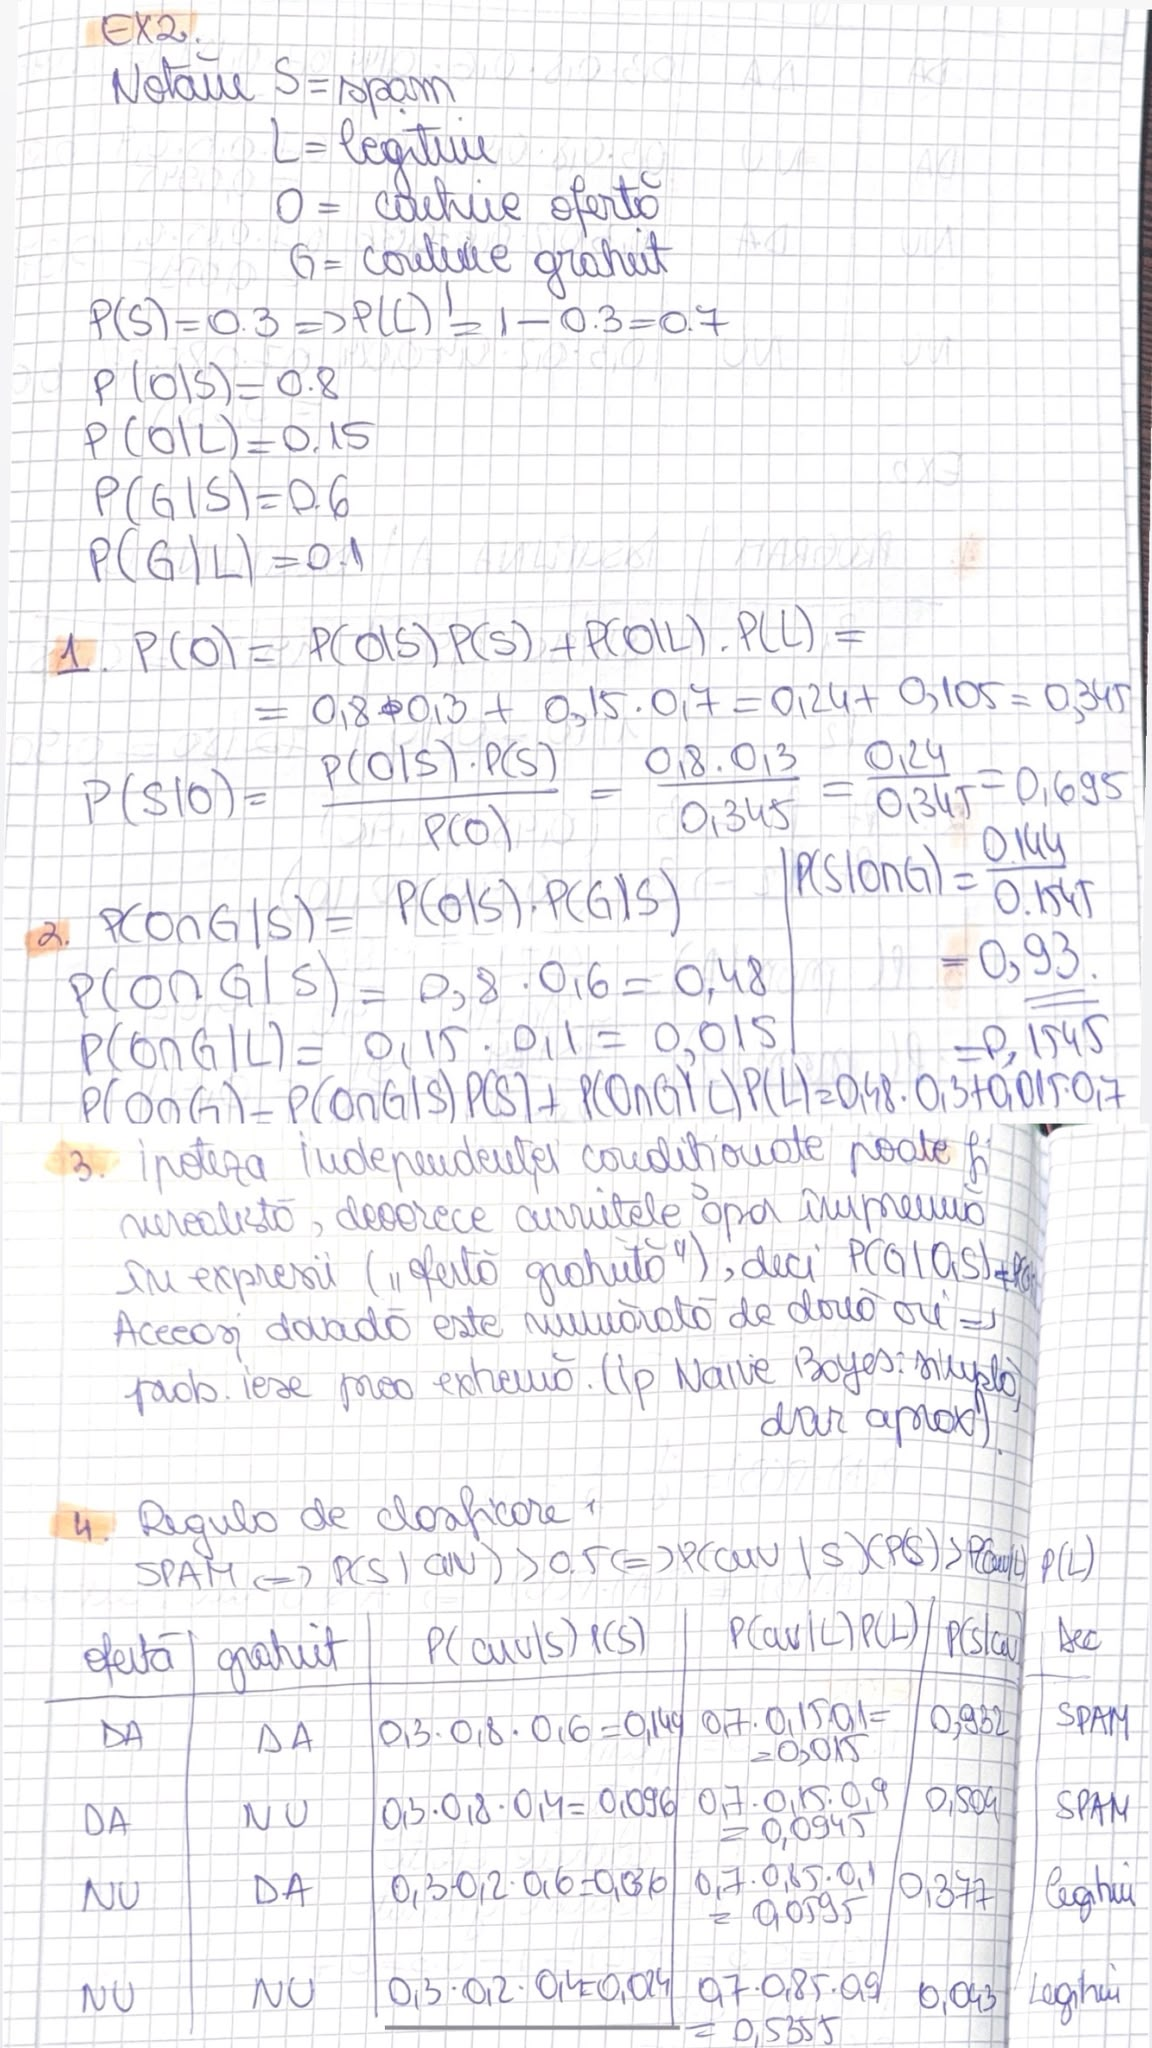

Să presupunem că un sistem de e-mail primește 30% mesaje spam. Nu putem ști sigur dacă un mesaj este spam, dar putem observa ce cuvinte conține. Știm că anumite cuvinte, precum „ofertă” sau „gratuit”, apar mult mai des în mesajele spam decât în cele legitime.

Notăm: $S$ = mesajul este spam, $L$ = mesajul este legitim, $O$ = conține „ofertă”, $G$ = conține „gratuit”.

Datele problemei:
- $P(S) = 0.3$, deci $P(L) = 1 - 0.3 = 0.7$
- $P(O \mid S) = 0.8$, $\quad P(O \mid L) = 0.15$
- $P(G \mid S) = 0.6$, $\quad P(G \mid L) = 0.1$

Obiectivul nostru: Să calculăm probabilitatea ca un mesaj să fie spam, știind ce cuvinte conține, și să construim o regulă simplă de clasificare.

## 2.1. Probabilitatea ca un mesaj care conține „ofertă” să fie spam
Căutăm $P(S \mid O)$. Enunțul ne dă invers, $P(O \mid S)$, așa că folosim formula lui Bayes.

**Formula probabilității totale** (un mesaj cu „ofertă” poate fi spam sau legitim):
$$P(O) = P(O \mid S)P(S) + P(O \mid L)P(L) = 0.8 \cdot 0.3 + 0.15 \cdot 0.7 = 0.24 + 0.105 = 0.345$$

**Regula lui Bayes:**
$$P(S \mid O) = \frac{P(O \mid S)P(S)}{P(O)} = \frac{0.24}{0.345} \approx 0.6957$$

Un mesaj care conține „ofertă” este spam cu probabilitatea de aproximativ **69.6%**.

## 2.2. Probabilitatea ca un mesaj care conține ambele cuvinte să fie spam
Căutăm $P(S \mid O \cap G)$.

**Independența condiționată:** știind clasa mesajului (spam sau legitim), apariția celor două cuvinte este independentă, deci înmulțim probabilitățile în fiecare clasă:
$$P(O \cap G \mid S) = P(O \mid S) \cdot P(G \mid S) = 0.8 \cdot 0.6 = 0.48$$
$$P(O \cap G \mid L) = P(O \mid L) \cdot P(G \mid L) = 0.15 \cdot 0.1 = 0.015$$

**Formula probabilității totale:**
$$P(O \cap G) = 0.48 \cdot 0.3 + 0.015 \cdot 0.7 = 0.144 + 0.0105 = 0.1545$$

**Regula lui Bayes:**
$$P(S \mid O \cap G) = \frac{P(O \cap G \mid S)P(S)}{P(O \cap G)} = \frac{0.144}{0.1545} \approx 0.9320$$

Al doilea cuvânt crește probabilitatea de spam de la 69.6% la **93.2%**.

In [7]:
#datele problemei
P_S = 0.3
P_L = 1 - P_S
P_O_S, P_O_L = 0.8, 0.15     # P(ofertă | spam), P(ofertă | legitim)
P_G_S, P_G_L = 0.6, 0.1      # P(gratuit | spam), P(gratuit | legitim)

# 2.1. P(S | O)
P_O = P_O_S * P_S + P_O_L * P_L
P_S_O = P_O_S * P_S / P_O

# 2.2. P(S | O și G), cu independență condiționată
numarator = P_O_S * P_G_S * P_S
numitor = numarator + P_O_L * P_G_L * P_L
P_S_OG = numarator / numitor

print("Calculăm probabilitățile cu formula lui Bayes...")
print(f"2.1. P(S | ofertă)           = {P_S_O:.4f}")
print(f"2.2. P(S | ofertă și gratuit) = {P_S_OG:.4f}")

Calculăm probabilitățile cu formula lui Bayes...
2.1. P(S | ofertă)           = 0.6957
2.2. P(S | ofertă și gratuit) = 0.9320


## Verificare prin Simulare
Simulăm 100.000 de mesaje: fiecare este spam cu probabilitatea 0.3, iar cuvintele apar independent, cu probabilitățile corespunzătoare clasei mesajului.

In [8]:
N = 100_000

spam = np.random.random(N) < P_S

#fiecare mesaj primește probabilitatea lui de a conține fiecare cuvânt
oferta = np.random.random(N) < np.where(spam, P_O_S, P_O_L)
gratuit = np.random.random(N) < np.where(spam, P_G_S, P_G_L)

p_S_O_sim = np.sum(spam & oferta) / np.sum(oferta)
p_S_OG_sim = np.sum(spam & oferta & gratuit) / np.sum(oferta & gratuit)

print(f"\nValoarea teoretică pentru 2.1: {P_S_O:.4f}")
print(f"Valoarea estimată pentru 2.1: {p_S_O_sim:.4f}")
print(f"\nValoarea teoretică pentru 2.2: {P_S_OG:.4f}")
print(f"Valoarea estimată pentru 2.2: {p_S_OG_sim:.4f}")


Valoarea teoretică pentru 2.1: 0.6957
Valoarea estimată pentru 2.1: 0.6978

Valoarea teoretică pentru 2.2: 0.9320
Valoarea estimată pentru 2.2: 0.9335


### Explicații:
- `np.random.random(N) < P_S`: fiecare mesaj este spam cu probabilitatea 0.3.
- `np.where(spam, P_O_S, P_O_L)`: fiecare mesaj primește probabilitatea lui de a conține „ofertă” (0.8 dacă este spam, 0.15 dacă este legitim).
- Cuvintele sunt generate separat, deci simularea respectă ipoteza de independență condiționată.
- Dintre mesajele care conțin cuvintele, numărăm câte sunt spam.

## Vizualizarea Actualizării Probabilității
Cum se schimbă probabilitatea ca mesajul să fie spam pe măsură ce aflăm ce cuvinte conține.

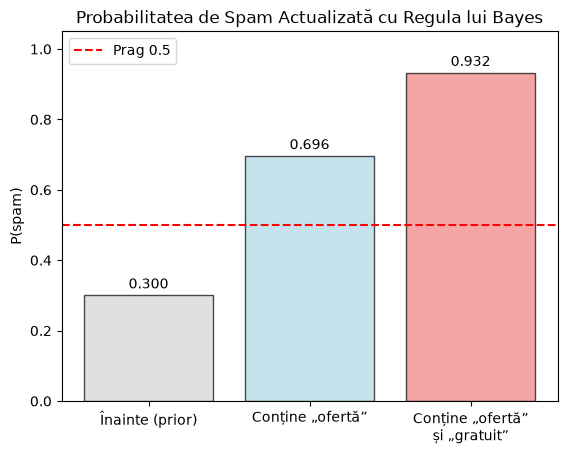

In [9]:
etape = ['Înainte (prior)', 'Conține „ofertă”', 'Conține „ofertă”\nși „gratuit”']
valori = [P_S, P_S_O, P_S_OG]

plt.bar(etape, valori, alpha=0.7, color=['lightgray', 'lightblue', 'lightcoral'], edgecolor='black')
plt.axhline(0.5, color='red', linestyle='--', label='Prag 0.5')
for i, v in enumerate(valori):
    plt.text(i, v + 0.02, f'{v:.3f}', ha='center')
plt.title('Probabilitatea de Spam Actualizată cu Regula lui Bayes')
plt.ylabel('P(spam)')
plt.ylim(0, 1.05)
plt.legend()
plt.show()

### Interpretare:
Fiecare cuvânt este o „dovadă” care actualizează probabilitatea: de la 30% (prior), la 69.6% după „ofertă” și la 93.2% după ambele cuvinte. Aceasta este ideea inferenței bayesiene: prior $\rightarrow$ date $\rightarrow$ posterior.

## 2.3. De ce poate fi nerealistă ipoteza independenței condiționate?
Ipoteza spune că, într-un mesaj spam, apariția cuvântului „ofertă” nu influențează apariția cuvântului „gratuit”. În realitate:
- cuvintele apar adesea **împreună**, în expresii fixe („ofertă gratuită”, „ofertă specială, transport gratuit”);
- într-un mesaj spam despre o promoție, dacă apare „ofertă”, este **mai probabil** să apară și „gratuit”, deci $P(G \mid O, S) \neq P(G \mid S)$;
- mesajele au teme: un e-mail de marketing conține grupuri de cuvinte legate între ele.

Consecința: înmulțind probabilitățile, numărăm de două ori aceeași „dovadă”, iar probabilitatea de spam iese prea extremă (prea aproape de 0 sau de 1). Totuși, ipoteza (folosită de clasificatorul **Naive Bayes**) simplifică mult calculele și funcționează bine în practică.

## 2.4. Regula de Clasificare
Pentru un mesaj nou, calculăm $P(S \mid \text{cuvinte})$ cu regula lui Bayes și clasificăm:

$$\text{mesajul este SPAM} \iff P(S \mid \text{cuvinte}) > 0.5$$

Echivalent, comparăm numărătorii din formula lui Bayes (numitorul este același):
$$P(\text{cuvinte} \mid S)\,P(S) > P(\text{cuvinte} \mid L)\,P(L)$$

Pragul 0.5 poate fi mărit (de exemplu la 0.9) dacă este mai grav să pierdem un mesaj legitim decât să lăsăm să treacă un spam.

In [10]:
def este_spam(are_oferta, are_gratuit, prag=0.5):
    # P(cuvinte | S) * P(S)
    s = P_S * (P_O_S if are_oferta else 1 - P_O_S) * (P_G_S if are_gratuit else 1 - P_G_S)
    # P(cuvinte | L) * P(L)
    l = P_L * (P_O_L if are_oferta else 1 - P_O_L) * (P_G_L if are_gratuit else 1 - P_G_L)
    p_spam = s / (s + l)
    return p_spam, p_spam > prag

print("Aplicăm regula de clasificare pentru toate combinațiile de cuvinte...")
for o in [True, False]:
    for g in [True, False]:
        p, decizie = este_spam(o, g)
        print(f"ofertă={o!s:5}  gratuit={g!s:5}  ->  P(S | cuvinte) = {p:.4f}  ->  {'SPAM' if decizie else 'LEGITIM'}")

Aplicăm regula de clasificare pentru toate combinațiile de cuvinte...
ofertă=True   gratuit=True   ->  P(S | cuvinte) = 0.9320  ->  SPAM
ofertă=True   gratuit=False  ->  P(S | cuvinte) = 0.5039  ->  SPAM
ofertă=False  gratuit=True   ->  P(S | cuvinte) = 0.3770  ->  LEGITIM
ofertă=False  gratuit=False  ->  P(S | cuvinte) = 0.0429  ->  LEGITIM


### Interpretare:
| ofertă | gratuit | $P(\text{cuv.} \mid S)\,P(S)$ | $P(\text{cuv.} \mid L)\,P(L)$ | $P(S \mid \text{cuvinte})$ | Decizie (prag 0.5) |
|---|---|---|---|---|---|
| da | da | $0.3 \cdot 0.8 \cdot 0.6 = 0.144$ | $0.7 \cdot 0.15 \cdot 0.1 = 0.0105$ | 0.932 | SPAM |
| da | nu | $0.3 \cdot 0.8 \cdot 0.4 = 0.096$ | $0.7 \cdot 0.15 \cdot 0.9 = 0.0945$ | 0.504 | SPAM (la limită) |
| nu | da | $0.3 \cdot 0.2 \cdot 0.6 = 0.036$ | $0.7 \cdot 0.85 \cdot 0.1 = 0.0595$ | 0.377 | LEGITIM |
| nu | nu | $0.3 \cdot 0.2 \cdot 0.4 = 0.024$ | $0.7 \cdot 0.85 \cdot 0.9 = 0.5355$ | 0.043 | LEGITIM |

Dacă un cuvânt **lipsește**, folosim complementul: de exemplu $P(\text{fără „gratuit”} \mid S) = 1 - 0.6 = 0.4$. Apoi $P(S \mid \text{cuvinte}) = \dfrac{\text{coloana 3}}{\text{coloana 3} + \text{coloana 4}}$.

Mesajul care conține doar „ofertă” este la limită: cu un prag mai strict (de exemplu 0.9), ar fi considerat legitim.

# Exercițiul 3: Paradoxul lui Simpson

## Calculele teoretice (foaia de lucru)
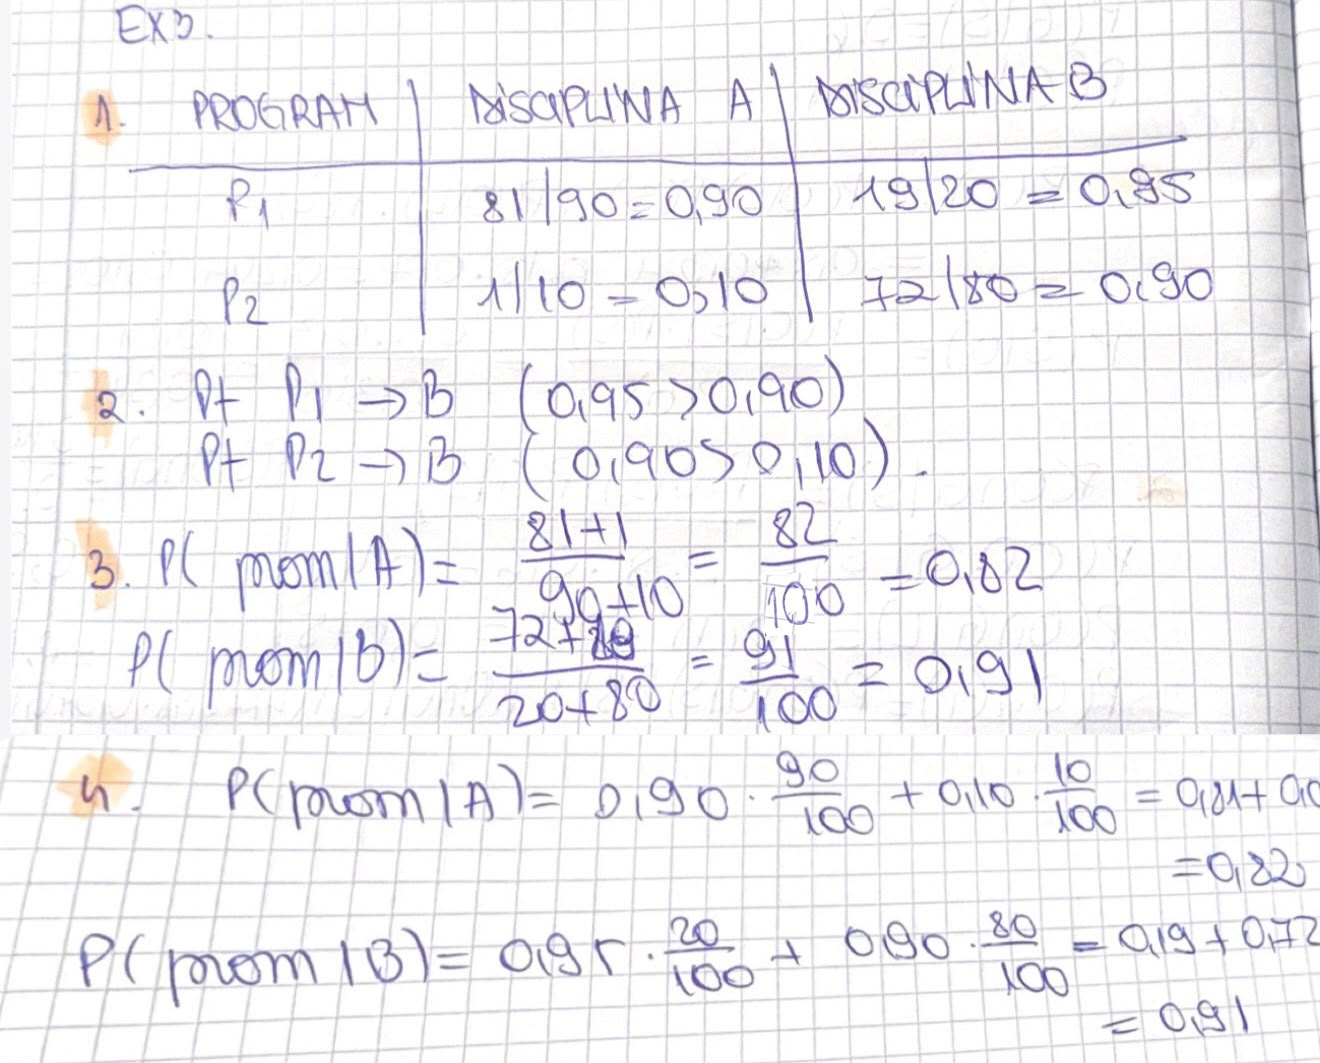


Să presupunem că o universitate analizează rata de promovare la două discipline, A și B, pentru studenții din două programe de studiu. Valorile reprezintă numărul studenților promovați din totalul celor evaluați.

| Program | Disciplina A | Disciplina B |
|---|---|---|
| Programul 1 | 81 din 90 | 19 din 20 |
| Programul 2 | 1 din 10 | 72 din 80 |

Obiectivul nostru: Să comparăm ratele de promovare pe programe și global și să înțelegem de ce concluziile trase din datele agregate pot fi diferite de cele trase pe grupuri (paradoxul lui Simpson).

## 3.1. Rata de promovare la fiecare disciplină, separat pe program
| Program | Disciplina A | Disciplina B |
|---|---|---|
| Programul 1 | $81/90 = 0.90$ | $19/20 = 0.95$ |
| Programul 2 | $1/10 = 0.10$ | $72/80 = 0.90$ |

## 3.2. Care disciplină are rata mai mare în fiecare program?
- Programul 1: $0.95 > 0.90$, deci **disciplina B**.
- Programul 2: $0.90 > 0.10$, deci **disciplina B**.

## 3.3. Rata globală de promovare
$$P(\text{promovat} \mid A) = \frac{81 + 1}{90 + 10} = \frac{82}{100} = 0.82$$
$$P(\text{promovat} \mid B) = \frac{19 + 72}{20 + 80} = \frac{91}{100} = 0.91$$

Global, tot **disciplina B** are rata mai mare.

## 3.4. De ce se poate inversa ordinea la agregare?
**Cu datele din enunț, ordinea NU se inversează**: B este mai bună în ambele programe și global. Paradoxul nu apare complet, dar efectul care îl produce se vede:
- în Programul 2 diferența dintre discipline este uriașă ($0.90 - 0.10 = 0.80$);
- global, diferența scade la doar $0.91 - 0.82 = 0.09$.

**De ce?** Studenții nu sunt împărțiți la fel între programe:
- la disciplina A, 90% dintre studenți sunt din Programul 1 (unde promovarea e mare);
- la disciplina B, 80% dintre studenți sunt din Programul 2.

Rata globală este o **medie ponderată**, iar ponderile diferă:
$$P(\text{prom} \mid A) = 0.90 \cdot \tfrac{90}{100} + 0.10 \cdot \tfrac{10}{100} = 0.82$$
$$P(\text{prom} \mid B) = 0.95 \cdot \tfrac{20}{100} + 0.90 \cdot \tfrac{80}{100} = 0.91$$

Disciplina A „ascunde” rezultatul slab din Programul 2, pentru că acolo are doar 10 studenți. **Ordinea s-ar inversa** dacă o disciplină ar fi mai bună în fiecare program, dar ar avea majoritatea studenților în programul cu rate mici: atunci media ei ponderată ar fi trasă în jos (vezi exemplul propriu de la 3.6).

## 3.5. Formularea în termeni de probabilități condiționate
Paradoxul lui Simpson apare când, pentru fiecare grup $P_i$:
$$P(\text{prom} \mid A, P_i) > P(\text{prom} \mid B, P_i)$$
dar, după agregare:
$$P(\text{prom} \mid A) < P(\text{prom} \mid B)$$

Este posibil pentru că, din **formula probabilității totale**:
$$P(\text{prom} \mid A) = \sum_i P(\text{prom} \mid A, P_i)\, P(P_i \mid A)$$

Ponderile $P(P_i \mid A)$ și $P(P_i \mid B)$ (cum sunt distribuiți studenții pe programe) **pot fi diferite**. Programul este o **variabilă de confuzie**: influențează atât disciplina, cât și rata de promovare.

## Verificarea Calculelor cu Pandas

In [11]:
#datele din enunț, într-un DataFrame
date = pd.DataFrame({
    'Program':    ['Programul 1', 'Programul 1', 'Programul 2', 'Programul 2'],
    'Disciplina': ['A', 'B', 'A', 'B'],
    'Promovati':  [81, 19, 1, 72],
    'Total':      [90, 20, 10, 80],
})
date['Rata'] = date['Promovati'] / date['Total']

print("3.1. Rata de promovare pe program:")
print(date.pivot(index='Program', columns='Disciplina', values='Rata').round(3))

globala = date.groupby('Disciplina')[['Promovati', 'Total']].sum()
globala['Rata'] = globala['Promovati'] / globala['Total']
print("\n3.3. Rata globală:")
print(globala.round(3))

3.1. Rata de promovare pe program:
Disciplina     A     B
Program               
Programul 1  0.9  0.95
Programul 2  0.1  0.90

3.3. Rata globală:
            Promovati  Total  Rata
Disciplina                        
A                  82    100  0.82
B                  91    100  0.91


### Explicații:
- `pd.DataFrame`: tabel cu datele din enunț, câte un rând pentru fiecare combinație program–disciplină.
- `date.pivot(...)`: rearanjează ratele într-un tabel cu programele pe rânduri și disciplinele pe coloane.
- `groupby('Disciplina')[...].sum()`: adună promovații și totalul pentru fiecare disciplină, indiferent de program (agregarea).

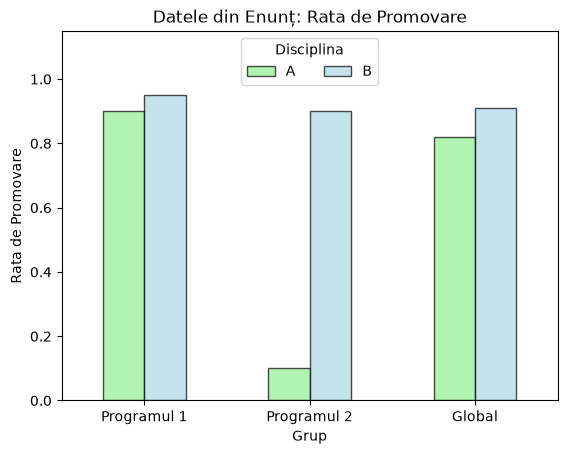

In [12]:
#afișăm grafic ratele pentru datele din enunț
grafic_enunt = date.pivot(index='Program', columns='Disciplina', values='Rata')
grafic_enunt.loc['Global'] = globala['Rata']

grafic_enunt.plot(kind='bar', alpha=0.7, color=['lightgreen', 'lightblue'], edgecolor='black', rot=0)
plt.title('Datele din Enunț: Rata de Promovare')
plt.xlabel('Grup')
plt.ylabel('Rata de Promovare')
plt.ylim(0, 1.15)
plt.legend(title='Disciplina', loc='upper center', ncol=2)
plt.show()

### Interpretare:
Bara albastră (disciplina B) este mai înaltă în toate cele trei grupuri: ordinea nu se inversează. Se vede însă cât de mult se micșorează diferența de la Programul 2 la nivel global.

## 3.6. Extensie Python: Exemplu Propriu de Paradox Simpson
Construim date în care **disciplina A este mai bună în fiecare program**, dar **disciplina B este mai bună global**.

In [13]:
exemplu = pd.DataFrame({
    'Program':    ['Programul 1', 'Programul 1', 'Programul 2', 'Programul 2'],
    'Disciplina': ['A', 'B', 'A', 'B'],
    'Promovati':  [18, 72, 24, 2],
    'Total':      [20, 90, 80, 10],
})
exemplu['Rata'] = exemplu['Promovati'] / exemplu['Total']

pe_program = exemplu.pivot(index='Program', columns='Disciplina', values='Rata')
print("Rata de promovare pe program:")
print(pe_program.round(3))

glob = exemplu.groupby('Disciplina')[['Promovati', 'Total']].sum()
glob['Rata'] = glob['Promovati'] / glob['Total']
print("\nRata globală:")
print(glob.round(3))

Rata de promovare pe program:
Disciplina     A    B
Program              
Programul 1  0.9  0.8
Programul 2  0.3  0.2

Rata globală:
            Promovati  Total  Rata
Disciplina                        
A                  42    100  0.42
B                  74    100  0.74


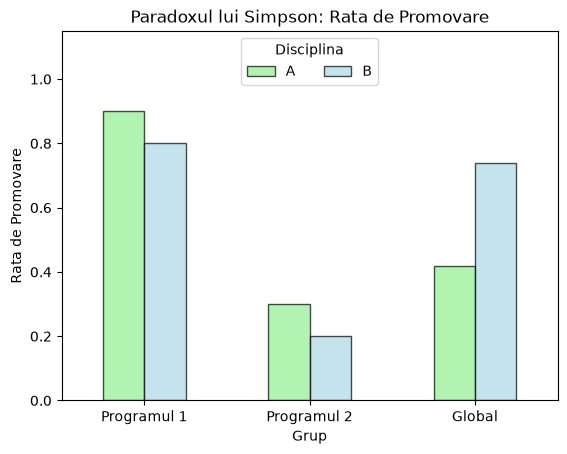

In [14]:
#afișăm grafic ratele pe program și global
tabel_grafic = pe_program.copy()
tabel_grafic.loc['Global'] = glob['Rata']

tabel_grafic.plot(kind='bar', alpha=0.7, color=['lightgreen', 'lightblue'], edgecolor='black', rot=0)
plt.title('Paradoxul lui Simpson: Rata de Promovare')
plt.xlabel('Grup')
plt.ylabel('Rata de Promovare')
plt.ylim(0, 1.15)
plt.legend(title='Disciplina', loc='upper center', ncol=2)
plt.show()

### Interpretare:
- **Programul 1**: A = 0.90 > B = 0.80
- **Programul 2**: A = 0.30 > B = 0.20
- **Global**: A = 0.42 < B = 0.74, deci **ordinea se inversează**.

Majoritatea studenților de la disciplina A (80 din 100) sunt în Programul 2, unde promovarea este mică pentru toți. La disciplina B, majoritatea (90 din 100) sunt în Programul 1, unde promovarea este mare. Când agregăm, ponderile diferite trag media lui A în jos și pe a lui B în sus.

Concluzie: înainte de a trage concluzii din date agregate, trebuie verificat dacă există o variabilă de confuzie (aici, programul de studiu).